<a href="https://colab.research.google.com/github/rodrigoviannasn/mat422-insulin-diabetes-project/blob/main/notebooks/01_data_audit_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Audit and Exploratory Data Analysis

**Project:** Assessing the Value of Two-Hour Serum Insulin for Diabetes Classification

## Notebook Goal

This notebook checks the raw dataset, describes the variables, examines zero and missing-value patterns, and creates initial visualizations. The analysis uses the unchanged CSV file stored in this project's GitHub repository.

This project is a dataset-label classification study. It does not make causal claims or provide medical advice.

In [1]:
# Import libraries and load the unchanged dataset from GitHub.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_URL = (
    "https://raw.githubusercontent.com/rodrigoviannasn/"
    "mat422-insulin-diabetes-project/main/data/diabetes.csv"
)

RANDOM_STATE = 422

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", context="notebook")

df = pd.read_csv(DATA_URL)

expected_columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome",
]

assert df.shape == (768, 9), f"Expected 768 rows and 9 columns, found {df.shape}."
assert df.columns.tolist() == expected_columns, "The column names do not match the expected dataset."
assert set(df["Outcome"].unique()) == {0, 1}, "Outcome must contain only 0 and 1."

print("Dataset loaded successfully.")
print(f"Shape: {df.shape[0]} rows × {df.shape[1]} columns")

display(df.head())

Dataset loaded successfully.
Shape: 768 rows × 9 columns


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 1. Data Quality Checks

The raw CSV has no blank cells, but some health measurements may contain zero values that could represent unrecorded measurements rather than true zeros. This notebook will first describe those patterns without changing the raw dataset.

In [2]:
# Check for explicit missing values, duplicate rows, and zero values.

from pathlib import Path

FIGURES_DIR = Path("results/figures")
TABLES_DIR = Path("results/tables")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

feature_columns = [column for column in df.columns if column != "Outcome"]

audit_summary = pd.DataFrame({
    "Data type": df[feature_columns].dtypes.astype(str),
    "Missing values": df[feature_columns].isna().sum(),
    "Zero values": df[feature_columns].eq(0).sum(),
    "Zero percentage": (df[feature_columns].eq(0).mean() * 100).round(1),
})

duplicate_rows = int(df.duplicated().sum())
explicit_missing_cells = int(df.isna().sum().sum())

print(f"Explicit missing cells: {explicit_missing_cells}")
print(f"Duplicate rows: {duplicate_rows}")

display(audit_summary)

audit_summary.to_csv(TABLES_DIR / "data_quality_summary.csv")

Explicit missing cells: 0
Duplicate rows: 0


,Data type,Missing values,Zero values,Zero percentage
Pregnancies,int64,0,111,14.5
Glucose,int64,0,5,0.7
BloodPressure,int64,0,35,4.6
SkinThickness,int64,0,227,29.6
Insulin,int64,0,374,48.7
BMI,float64,0,11,1.4
DiabetesPedigreeFunction,float64,0,0,0.0
Age,int64,0,0,0.0


## 2. Zero-Value Pattern in Potentially Affected Measurements

A zero pregnancy count can be valid. However, a zero value for glucose, blood pressure, skin thickness, insulin, or BMI may be unrealistic. I will treat these as possible missing values only in a later sensitivity analysis; I will not alter the raw data here.

,Variable,Zero values,Zero percentage
0,Glucose,5,0.7
1,BloodPressure,35,4.6
2,SkinThickness,227,29.6
3,Insulin,374,48.7
4,BMI,11,1.4


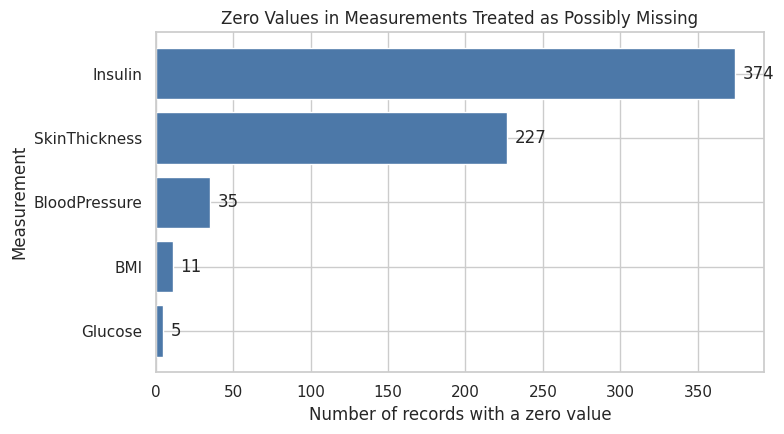

In [3]:
# Summarize and visualize zero values in measurements where zero may be unrealistic.

possible_missing_zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
]

zero_value_summary = pd.DataFrame({
    "Variable": possible_missing_zero_columns,
    "Zero values": [
        int((df[column] == 0).sum())
        for column in possible_missing_zero_columns
    ],
})

zero_value_summary["Zero percentage"] = (
    zero_value_summary["Zero values"] / len(df) * 100
).round(1)

display(zero_value_summary)

zero_value_summary.to_csv(
    TABLES_DIR / "possible_missing_zero_summary.csv",
    index=False,
)

plot_data = zero_value_summary.sort_values("Zero values")

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(
    plot_data["Variable"],
    plot_data["Zero values"],
    color="#4C78A8",
)

ax.set_title("Zero Values in Measurements Treated as Possibly Missing")
ax.set_xlabel("Number of records with a zero value")
ax.set_ylabel("Measurement")

for bar, count in zip(bars, plot_data["Zero values"]):
    ax.text(
        bar.get_width() + 5,
        bar.get_y() + bar.get_height() / 2,
        str(count),
        va="center",
    )

plt.tight_layout()
fig.savefig(
    FIGURES_DIR / "zero_value_counts.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 3. Outcome Balance

This section shows the number and percentage of records in each recorded outcome group. Because the two groups are not equally sized, later model evaluation will use stratified cross-validation.

,Label,Records,Percentage
0,Outcome = 0,500,65.1
1,Outcome = 1,268,34.9


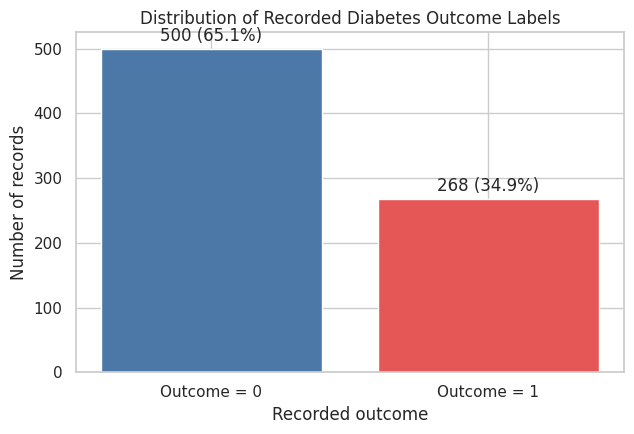

In [4]:
# Summarize and visualize the distribution of recorded outcome labels.

outcome_summary = (
    df["Outcome"]
    .value_counts()
    .sort_index()
    .rename_axis("Outcome")
    .reset_index(name="Records")
)

outcome_summary["Label"] = outcome_summary["Outcome"].map({
    0: "Outcome = 0",
    1: "Outcome = 1",
})

outcome_summary["Percentage"] = (
    outcome_summary["Records"] / len(df) * 100
).round(1)

display(outcome_summary[["Label", "Records", "Percentage"]])

outcome_summary.to_csv(
    TABLES_DIR / "outcome_balance_summary.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(6.5, 4.5))

bars = ax.bar(
    outcome_summary["Label"],
    outcome_summary["Records"],
    color=["#4C78A8", "#E45756"],
)

ax.set_title("Distribution of Recorded Diabetes Outcome Labels")
ax.set_xlabel("Recorded outcome")
ax.set_ylabel("Number of records")

for bar, count, percentage in zip(
    bars,
    outcome_summary["Records"],
    outcome_summary["Percentage"],
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 12,
        f"{count} ({percentage}%)",
        ha="center",
    )

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "outcome_balance.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 4. Key Predictor Distributions by Outcome

This section compares glucose, BMI, insulin, and age across the two recorded outcome groups. These plots are descriptive only. They help identify patterns in the dataset but do not prove that any variable causes diabetes.

Outcome,Variable,Outcome = 0,Outcome = 1
0,Glucose,107.00,140.00
1,BMI,30.05,34.25
2,Insulin,39.00,0.00
3,Age,27.00,36.00


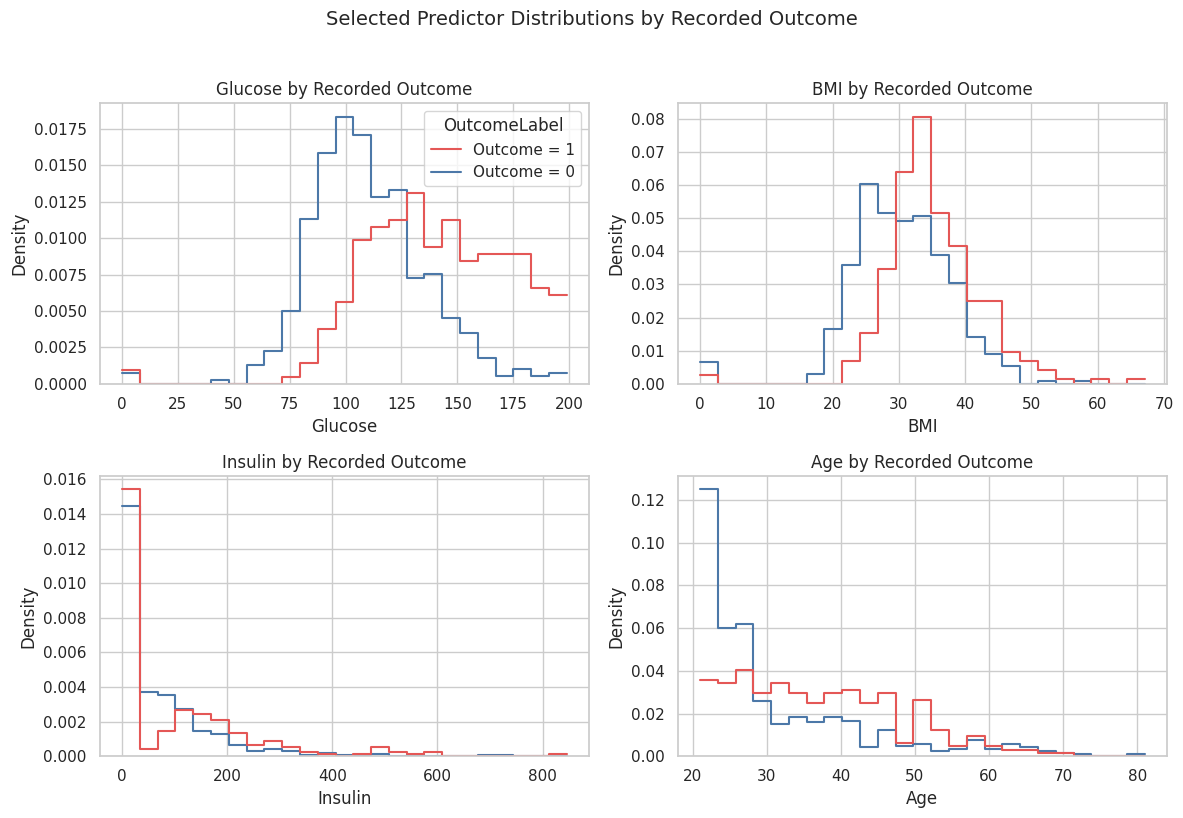

In [5]:
# Compare selected predictor distributions across recorded outcome groups.

key_features = ["Glucose", "BMI", "Insulin", "Age"]

plot_df = df.assign(
    OutcomeLabel=df["Outcome"].map({
        0: "Outcome = 0",
        1: "Outcome = 1",
    })
)

median_by_outcome = (
    df.groupby("Outcome")[key_features]
    .median()
    .rename(index={
        0: "Outcome = 0",
        1: "Outcome = 1",
    })
    .T
    .rename_axis("Variable")
    .reset_index()
)

display(median_by_outcome)

median_by_outcome.to_csv(
    TABLES_DIR / "median_by_outcome.csv",
    index=False,
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

palette = {
    "Outcome = 0": "#4C78A8",
    "Outcome = 1": "#E45756",
}

for index, (ax, feature) in enumerate(zip(axes, key_features)):
    sns.histplot(
        data=plot_df,
        x=feature,
        hue="OutcomeLabel",
        bins=25,
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        palette=palette,
        ax=ax,
    )

    ax.set_title(f"{feature} by Recorded Outcome")
    ax.set_xlabel(feature)
    ax.set_ylabel("Density")

    if index != 0 and ax.get_legend() is not None:
        ax.get_legend().remove()

fig.suptitle(
    "Selected Predictor Distributions by Recorded Outcome",
    fontsize=14,
    y=1.02,
)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "key_predictor_distributions.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 5. Insulin-Focused Exploration

Insulin is the main feature in this project. Because many records have an insulin value of zero, I will first show how often zero occurs in each outcome group. I will then compare positive insulin values only for visualization purposes. The raw data will remain unchanged.

,Outcome label,Records,Zero insulin records,Zero insulin percentage,Median positive insulin
0,Outcome = 0,500,236,47.2,102.5
1,Outcome = 1,268,138,51.5,169.5


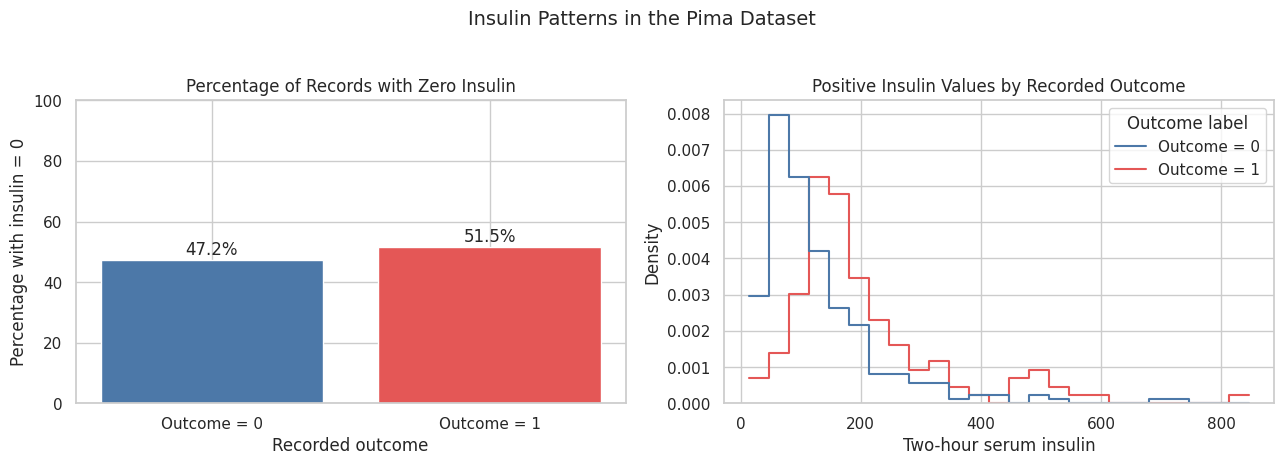

In [6]:
# Examine zero and positive insulin values by recorded outcome group.

insulin_summary = (
    df.groupby("Outcome")["Insulin"]
    .agg(
        Records="size",
        ZeroInsulin=lambda values: int((values == 0).sum()),
        MedianPositiveInsulin=lambda values: values[values > 0].median(),
    )
    .reindex([0, 1])
    .reset_index()
)

insulin_summary["Outcome label"] = insulin_summary["Outcome"].map({
    0: "Outcome = 0",
    1: "Outcome = 1",
})

insulin_summary["Zero insulin percentage"] = (
    insulin_summary["ZeroInsulin"] / insulin_summary["Records"] * 100
).round(1)

insulin_summary = insulin_summary[
    [
        "Outcome label",
        "Records",
        "ZeroInsulin",
        "Zero insulin percentage",
        "MedianPositiveInsulin",
    ]
].rename(columns={
    "ZeroInsulin": "Zero insulin records",
    "MedianPositiveInsulin": "Median positive insulin",
})

display(insulin_summary)

insulin_summary.to_csv(
    TABLES_DIR / "insulin_zero_pattern_by_outcome.csv",
    index=False,
)

positive_insulin = df.loc[df["Insulin"] > 0].copy()
positive_insulin["Outcome label"] = positive_insulin["Outcome"].map({
    0: "Outcome = 0",
    1: "Outcome = 1",
})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

bars = axes[0].bar(
    insulin_summary["Outcome label"],
    insulin_summary["Zero insulin percentage"],
    color=["#4C78A8", "#E45756"],
)

axes[0].set_title("Percentage of Records with Zero Insulin")
axes[0].set_xlabel("Recorded outcome")
axes[0].set_ylabel("Percentage with insulin = 0")
axes[0].set_ylim(0, 100)

for bar, percentage in zip(
    bars,
    insulin_summary["Zero insulin percentage"],
):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{percentage}%",
        ha="center",
    )

sns.histplot(
    data=positive_insulin,
    x="Insulin",
    hue="Outcome label",
    bins=25,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    palette={
        "Outcome = 0": "#4C78A8",
        "Outcome = 1": "#E45756",
    },
    ax=axes[1],
)

axes[1].set_title("Positive Insulin Values by Recorded Outcome")
axes[1].set_xlabel("Two-hour serum insulin")
axes[1].set_ylabel("Density")

fig.suptitle("Insulin Patterns in the Pima Dataset", fontsize=14, y=1.03)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "insulin_patterns_by_outcome.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 6. Correlation Analysis

This section uses Pearson correlation to describe linear relationships among the variables in the raw dataset. Correlation does not prove causation. In particular, the insulin correlation may be affected by the large number of recorded zero values.

,Variable,Pearson correlation with Outcome,AbsoluteCorrelation
0,Glucose,0.466581,0.466581
1,BMI,0.292695,0.292695
2,Age,0.238356,0.238356
3,Pregnancies,0.221898,0.221898
4,DiabetesPedigreeFunction,0.173844,0.173844
5,Insulin,0.130548,0.130548
6,SkinThickness,0.074752,0.074752
7,BloodPressure,0.065068,0.065068


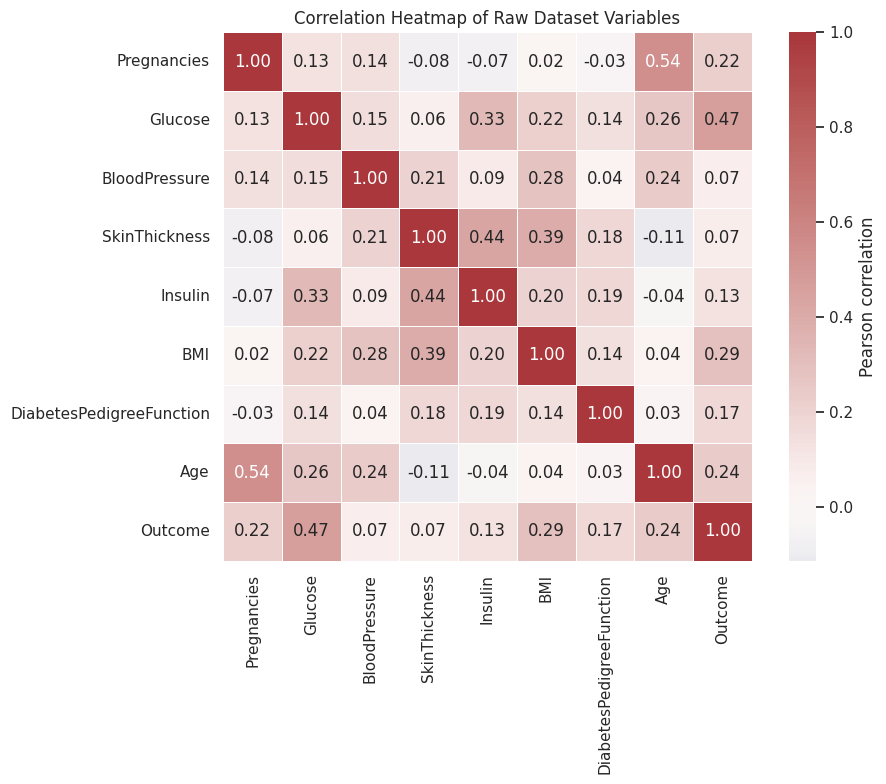

In [7]:
# Calculate correlations using the unchanged raw dataset.

correlation_matrix = df.corr(numeric_only=True)

outcome_correlation_summary = (
    correlation_matrix["Outcome"]
    .drop("Outcome")
    .rename("Pearson correlation with Outcome")
    .to_frame()
    .assign(
        AbsoluteCorrelation=lambda table: (
            table["Pearson correlation with Outcome"].abs()
        )
    )
    .sort_values("AbsoluteCorrelation", ascending=False)
    .reset_index()
    .rename(columns={"index": "Variable"})
)

display(outcome_correlation_summary)

outcome_correlation_summary.to_csv(
    TABLES_DIR / "outcome_correlations.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    cmap="vlag",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Pearson correlation"},
    ax=ax,
)

ax.set_title("Correlation Heatmap of Raw Dataset Variables")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()